# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with Gate 2 = GO / Gate 3 = NA the manifold is non-branching, so the
branching-only correlation (04) and modules (05) notebooks are not produced — this unconditional
EMT-TF expression notebook follows signatures directly and is the final notebook.)*

Puram 2017 overlays two EMT-TFs marking the *two ends* of its branching trajectory. Per the
**derive-don't-inherit** mandate we do not inherit that pair: we score a candidate EMT-TF panel — the
canonical Snail/Zeb/Twist factors **plus the mesenchymal / neural-crest FOXC and PRRX factors** —
along *this* trajectory (Gast/pSom-high body → neural-crest terminus) and read each factor's
direction of effect from the data, gated on detectable expression. VIM (vimentin) is a mesenchymal
**marker**, not a transcription factor, and is excluded.

**Honest readout for this dataset (reported, not forced into the Puram two-end template).** On this
non-branching CLL manifold **every** expressed EMT-TF rises toward the neural-crest terminus
(all Spearman ρ vs pseudotime are ≥ 0) — there is **no genuine root-end EMT-TF**. ZEB2 is the
dominant terminus factor (highest expression fraction and ρ); PRRX1 is the **least terminus-biased**
of the panel (ρ ≈ 0, nearly flat) but is still not a root marker. We overlay ZEB2 (terminus) against
PRRX1 (least-terminal) to show the panel's span, and state plainly that the EMT-TF gradient here is
monotonic toward the terminus rather than a two-ended root↔terminus pair. Deliverable: `expression.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the rooted, signature-scored manifold

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(float(t.min()),2), '->', round(float(t.max()),2))

cells: 672 | pseudotime range 0.0 -> 8.92


### Score the EMT-TF panel and read direction of effect (data-driven)
For each candidate TF: fraction of cells expressing it, mean expression in the early (root) vs late
(terminus) pseudotime tercile, and Spearman correlation with pseudotime. A negative ρ (sufficiently
expressed) would mark a root-end factor; a positive ρ marks a terminus factor. The panel widens
beyond Snail/Zeb/Twist to the FOXC and PRRX families (the Kürten lesson: canonical factors alone miss
end-specific regulators). Factors below a 3% expression floor are too sparse to overlay.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
missing = [g for g in panel if g not in adata.var_names]
print('panel present:', present, '| absent from matrix:', missing)
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho,p = spearmanr(tn, x)
    rows.append((g, round(float(expr.mean()),3), round(float(x[early].mean()),3),
                 round(float(x[late].mean()),3), round(float(rho),3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
# Honest reading: is there a genuine root-end factor (negative rho, expressed)?
root_candidates = ok[ok.rho_vs_t < 0]
has_root = len(root_candidates) > 0
terminus_tf = ok.sort_values('rho_vs_t').iloc[-1]['TF']   # most terminus-biased
least_term_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']  # least terminus-biased (closest to root end)
print(f'\nall expressed EMT-TFs have rho >= 0: {bool((ok.rho_vs_t>=0).all())} '
      f'-> no genuine root-end EMT-TF on this non-branching manifold')
print(f'terminus factor = {terminus_tf} (most positive rho); '
      f'least terminus-biased = {least_term_tf} (rho ~ 0, not a root marker)')

panel present: ['SNAI1', 'SNAI2', 'ZEB1', 'ZEB2', 'TWIST1', 'TWIST2', 'FOXC1', 'FOXC2', 'PRRX1', 'PRRX2'] | absent from matrix: []
    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 PRRX1      0.141       0.244      0.301     0.012 LATE(terminus)
 SNAI2      0.007       0.000      0.009     0.054 LATE(terminus)
 SNAI1      0.051       0.019      0.068     0.073 LATE(terminus)
TWIST2      0.116       0.056      0.120     0.079 LATE(terminus)
 FOXC1      0.140       0.106      0.180     0.086 LATE(terminus)
TWIST1      0.070       0.038      0.092     0.101 LATE(terminus)
 PRRX2      0.110       0.051      0.140     0.114 LATE(terminus)
 FOXC2      0.146       0.078      0.170     0.155 LATE(terminus)
  ZEB1      0.490       0.805      1.700     0.236 LATE(terminus)
  ZEB2      0.655       1.393      2.728     0.309 LATE(terminus)

all expressed EMT-TFs have rho >= 0: True -> no genuine root-end EMT-TF on this non-branching manifold
terminus factor = ZEB2 (most positive r

### EMT-TF expression overlay (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right, `size=30`. Draw order is set by abundance
(the more widely-expressed factor first, the sparser on top) so neither marker is occluded. Each
factor is thresholded at the upper quartile of expression among its expressing cells, so only the
strongest expressers show. This categorical overlay of thresholded expressers on a grey manifold is
the reference plotting style (not a continuous single-gene colormap). The two overlaid factors span
the panel — ZEB2 (terminus) vs the least terminus-biased factor — rather than a forced root↔terminus
pair, since the data show no root-end EMT-TF here.

overlay thresholds (upper quartile among expressers): {'PRRX1': 2.803, 'ZEB2': 4.307} | cells shown: {'PRRX1': 24, 'ZEB2': 110}
PRRX1: 14.1% expressing; 24 shown (upper quartile), mean pseudotime of shown cells = 0.67 (all cells = 0.59)
ZEB2: 65.5% expressing; 110 shown (upper quartile), mean pseudotime of shown cells = 0.79 (all cells = 0.59)
note: both factors sit at or above mean pseudotime -> no root-end EMT-TF; ZEB2 is the terminus factor
saved expression.pdf


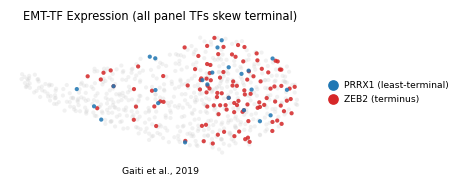

In [5]:
term_tf = terminus_tf; other_tf = least_term_tf
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [other_tf, term_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [other_tf, term_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [other_tf, term_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [other_tf, term_tf]})
order = sorted([other_tf, term_tf], key=lambda g: -int(sel[g].sum()))
colors = {other_tf:'tab:blue', term_tf:'tab:red'}
labs = {other_tf: f'{other_tf} (least-terminal)', term_tf: f'{term_tf} (terminus)'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
from matplotlib.lines import Line2D
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.legend(handles=[Line2D([],[],marker='o',ls='',color=colors[g],label=labs[g]) for g in [other_tf,term_tf]],
          frameon=False, loc='center left', bbox_to_anchor=(1.02,.5), fontsize=6, handletextpad=.2)
ax.set_title('EMT-TF Expression (all panel TFs skew terminal)', size=7.5)
ax.text(.5,-.14,'Gaiti et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [other_tf, term_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
print('note: both factors sit at or above mean pseudotime -> no root-end EMT-TF; ZEB2 is the terminus factor')
print('saved expression.pdf')